# PyXDM vs postg

Hirshfeld XDM moments, volumes and charges of PyXDM and postg for 20 molecules with H, C, N, O and S, from the same
B3LYP/cc-pVTZ wavefunctions (`results/comparison.csv` from `compare.py`, `results/proatoms.csv` from
`proatom_test.py`). Differences are PyXDM minus postg, per atom: relative to postg, in %, for the moments and volumes,
and absolute, in e, for the charges.

In [ ]:
import os

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

In [ ]:
figure_dir = "figures"
os.makedirs(figure_dir, exist_ok=True)

sns.set(style="whitegrid", palette="colorblind", context="paper", font_scale=1.5)

# The two runs of each figure: first and second colours of the colorblind palette
COLORS = sns.color_palette("colorblind")[:2]
# Figures saved as in the other SI notebooks
SAVE = {"bbox_inches": "tight", "dpi": 300, "transparent": True}

QUANTITIES = ["<M1^2>", "<M2^2>", "<M3^2>", "volume", "charge"]
LABELS = {
    "<M1^2>": r"$\langle M_1^2 \rangle$",
    "<M2^2>": r"$\langle M_2^2 \rangle$",
    "<M3^2>": r"$\langle M_3^2 \rangle$",
    "volume": "Volume",
    "charge": "Charge",
}
UNITS = {quantity: "e" if quantity == "charge" else "%" for quantity in QUANTITIES}

### Load the results

In [ ]:
def difference(table, method, reference="postg"):
    """
    Difference of a method from a reference, per atom and quantity.

    Parameters
    ----------
    table : pd.DataFrame
        One row per atom and quantity, one column per method.
    method : str
        Column of the method.
    reference : str, optional
        Column of the reference (default is "postg").

    Returns
    -------
    pd.Series
        method - reference: relative to the reference, in %, for the moments and volumes; absolute, in e, for the charges.
    """
    absolute = table[method] - table[reference]
    return (100 * absolute / table[reference]).where(table["quantity"] != "charge", absolute)


def summary(runs):
    """
    Mean and maximum absolute difference per quantity, over all atoms.

    Parameters
    ----------
    runs : dict[str, pd.Series]
        Differences of each run, by name.

    Returns
    -------
    pd.DataFrame
        One row per quantity, columns (run, "mean") and (run, "max").
    """
    stats = {name: diff.abs().groupby(table["quantity"]).agg(["mean", "max"]).reindex(QUANTITIES) for name, diff in runs.items()}
    return pd.concat(stats, axis=1)


# One row per atom and quantity, one column per method
data = pd.concat([pd.read_csv("results/comparison.csv"), pd.read_csv("results/proatoms.csv")])
table = data.pivot_table(index=["molecule", "atom", "element", "quantity"], columns="method", values="value").reset_index()

atoms = table[table["quantity"] == "charge"]
print(f"{atoms['molecule'].nunique()} molecules, {len(atoms)} atoms:", atoms["element"].value_counts().to_dict())

20 molecules, 283 atoms: {'H': 154, 'C': 107, 'O': 16, 'N': 4, 'S': 2}


### 1. Same mesh and Hirshfeld weights

PyXDM on postg's mesh and Hirshfeld weights (`--mesh`, `--weights`), so that both programs integrate on the same
points with the same weights; then also with postg's density cutoff for the Becke-Roussel displacement (b = 0 where
the spin density is below 1e-10). Mean and maximum absolute difference from postg:

In [ ]:
SAME_INPUT_RUNS = {"mesh and weights": "pyxdm_postg_inputs", "mesh, weights and cutoff": "pyxdm_postg_cutoff"}
same_inputs = {name: difference(table, method) for name, method in SAME_INPUT_RUNS.items()}
summary(same_inputs).style.format("{:.1e}")

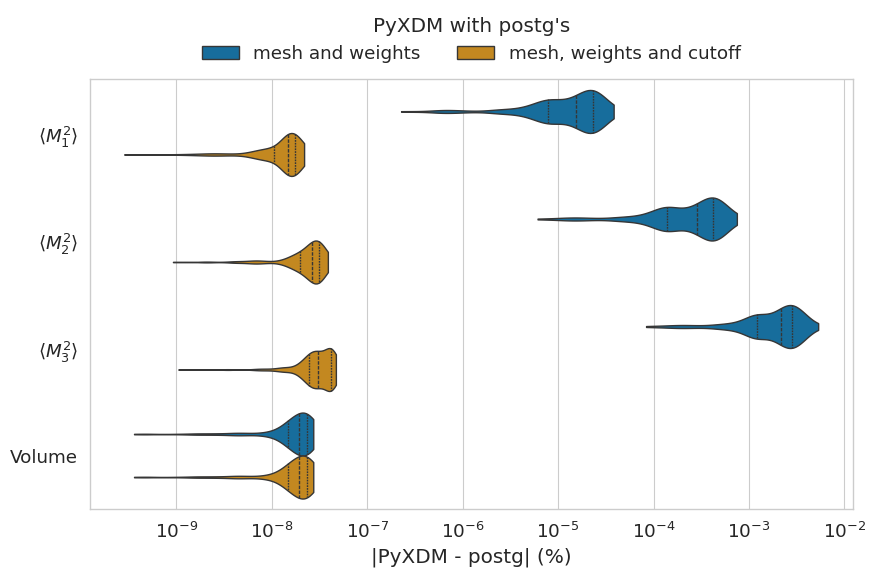

In [ ]:
# |PyXDM - postg| of every atom, log scale; the charges (in e) are in the table above
rows = table["quantity"] != "charge"
plot_data = pd.concat(
    [
        pd.DataFrame({"quantity": table.loc[rows, "quantity"], "PyXDM with postg's": name, "difference": diff[rows].abs()})
        for name, diff in same_inputs.items()
    ]
)

fig, ax = plt.subplots(figsize=(9, 6))
sns.violinplot(
    data=plot_data,
    x="difference",
    y="quantity",
    hue="PyXDM with postg's",
    order=QUANTITIES[:4],
    palette=COLORS,
    log_scale=True,
    cut=0,
    inner="quart",
    density_norm="width",
    ax=ax,
)
ax.set_yticks(range(4), [LABELS[q] for q in QUANTITIES[:4]])
ax.set_xlabel("|PyXDM - postg| (%)")
ax.set_ylabel("")
sns.move_legend(ax, "lower center", bbox_to_anchor=(0.5, 1.0), ncol=2, frameon=False)
plt.tight_layout()
plt.savefig(os.path.join(figure_dir, "same_inputs.pdf"), **SAVE)
plt.show()

### 2. Each program with its own defaults, and the pro-atoms

postg with its own mesh and built-in free-atom densities; PyXDM with its default `fine` grid and Hirshfeld weights
from the B3LYP/cc-pVTZ pro-atom database in `proatomdb/`. The second PyXDM run uses the same `fine` grid with
Hirshfeld weights from postg's free-atom densities (`proatom_test.py`), so that only the pro-atoms change ("B3LYP"
and "postg" below). Mean and maximum absolute difference from postg:

In [ ]:
PROATOM_RUNS = {"B3LYP": "pyxdm_fine", "postg": "pyxdm_fine_postg_proatoms"}
differences = {name: difference(table, method) for name, method in PROATOM_RUNS.items()}
summary({f"{name} pro-atoms": diff for name, diff in differences.items()}).style.format("{:.2f}").format(
    "{:.1e}", subset=pd.IndexSlice["charge", :]
)

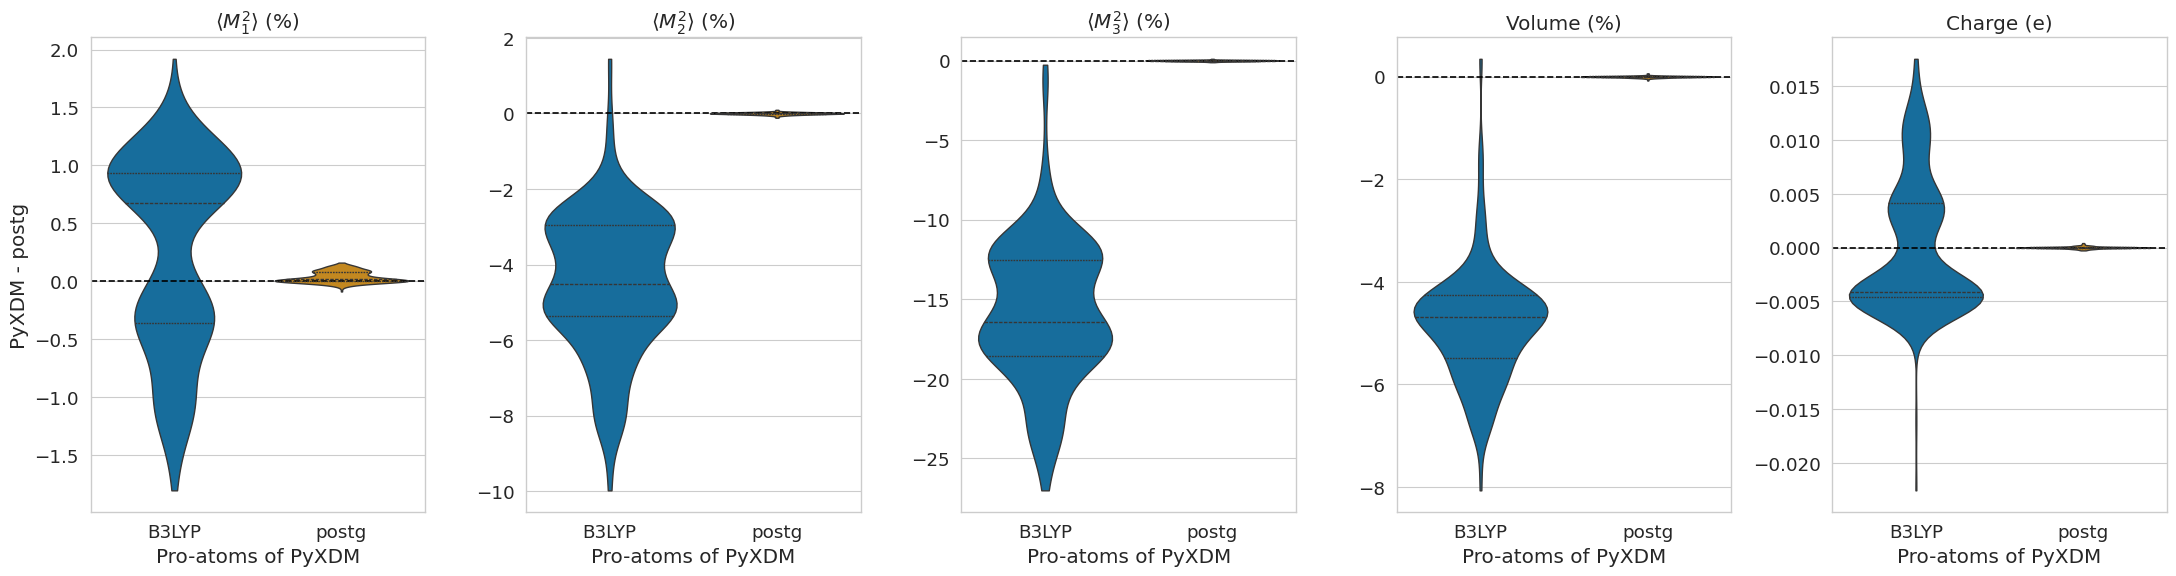

In [ ]:
def plot_violins(differences, xlabel, path):
    """
    Distribution of the per-atom differences from postg of two PyXDM runs, one panel per quantity.

    Parameters
    ----------
    differences : dict[str, pd.Series]
        Differences of each run, by name.
    xlabel : str
        Label of the runs.
    path : str
        Output PDF.
    """
    plot_data = pd.concat(
        [pd.DataFrame({"quantity": table["quantity"], "run": name, "difference": diff}) for name, diff in differences.items()]
    )
    fig, axes = plt.subplots(nrows=1, ncols=5, figsize=(22, 6))
    for ax, quantity in zip(axes, QUANTITIES):
        rows = plot_data[plot_data["quantity"] == quantity]
        ax.axhline(0.0, color="black", linestyle="--")
        sns.violinplot(
            data=rows,
            x="run",
            y="difference",
            hue="run",
            palette=COLORS,
            cut=0,
            inner="quart",
            density_norm="width",
            legend=False,
            ax=ax,
        )
        ax.set_title(f"{LABELS[quantity]} ({UNITS[quantity]})")
        ax.set_xlabel(xlabel)
        ax.set_ylabel("PyXDM - postg" if ax is axes[0] else "")
    plt.tight_layout()
    plt.savefig(path, **SAVE)
    plt.show()


plot_violins(differences, "Pro-atoms of PyXDM", os.path.join(figure_dir, "proatoms.pdf"))

### 3. Grid convergence of PyXDM

The `fine` and `veryfine` grids against `ultrafine`, with the B3LYP/cc-pVTZ pro-atoms, in the same units:

In [ ]:
summary(
    {f"{grid} vs ultrafine": difference(table, f"pyxdm_{grid}", reference="pyxdm_ultrafine") for grid in ("fine", "veryfine")}
).style.format("{:.3f}").format("{:.1e}", subset=pd.IndexSlice["charge", :])